### 문장을 벡터로 변환
- 문장을 숫자 배열로 변경
- 벡터 : 숫자 배열
- 차원 : 벡터 개수

| 문장 | 느리고 | 배송 | 별로 | 빠르고 | 좋아요 | 최고 |
|--|--|--|--|--|--|--|
|배송 빠르고 좋아요 | 0 | 1 | 0 | 1 | 1 | 0 |
|배송 느리고 별로 | 1 | 1 | 1 | 0 | 0 | 0 |
|좋아요 좋아요 최고 | 0 | 0 | 0 | 0 | 2 | 1 |


In [72]:
# 사이킷런
from sklearn.feature_extraction.text import CountVectorizer

In [73]:
docs = ['배송 빠르고 좋아요','배송 느리고 별로','좋아요 좋아요 최고']

vec = CountVectorizer()
X = vec.fit_transform(docs) # fit: 단어장 만들기 / transform: 문장을 숫자로 변경
X

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 8 stored elements and shape (3, 6)>

In [74]:
# 단어장 확인
vec.get_feature_names_out()

array(['느리고', '배송', '별로', '빠르고', '좋아요', '최고'], dtype=object)

In [75]:
X.toarray()

array([[0, 1, 0, 1, 1, 0],
       [1, 1, 1, 0, 0, 0],
       [0, 0, 0, 0, 2, 1]])

In [76]:
X.shape

(3, 6)

### 네이버 영화 리뷰 데이터

In [77]:
# from google.colab import drive
# drive.mount('/content/gdrive')

In [78]:
# github 네이버 영화리뷰 데이터 가져오기
import pandas as pd

url = 'https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt'
nsmc = pd.read_csv(url, sep='\t')
nsmc.shape


(150000, 3)

In [79]:
nsmc.head(5)

,id,document,label
0,9976970,아 더빙.. 진짜 짜증나네요 목소리,0
1,3819312,흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나,1
2,10265843,너무재밓었다그래서보는것을추천한다,0
3,9045019,교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정,0
4,6483659,사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 ...,1


In [80]:
nsmc.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   id        150000 non-null  int64
 1   document  149995 non-null  str  
 2   label     150000 non-null  int64
dtypes: int64(2), str(1)
memory usage: 3.4 MB


In [81]:
# null 데이터 제거

# nsmc.drop()

nsmc = nsmc.dropna()

# 중복 리뷰 데이터 제거
nsmc = nsmc.drop_duplicates('document')
nsmc.info()

<class 'pandas.DataFrame'>
Index: 146182 entries, 0 to 149999
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   id        146182 non-null  int64
 1   document  146182 non-null  str  
 2   label     146182 non-null  int64
dtypes: int64(2), str(1)
memory usage: 4.5 MB


In [82]:
# document => text 컬럼명 변경

#nsmc.columns = ['id', 'text', 'label']
#nsmc.head(5)

nsmc = nsmc.rename(columns={'document':'text'})[['text','label']]
nsmc.head(3)

,text,label
0,아 더빙.. 진짜 짜증나네요 목소리,0
1,흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나,1
2,너무재밓었다그래서보는것을추천한다,0


In [83]:
# 임의로 긍정,부정 각 1000 개 추출 => 2000 개

df = nsmc.groupby('label').sample(1000,random_state=42)
df['label'].value_counts()

label
0    1000
1    1000
Name: count, dtype: int64

In [84]:
# 저장
# 복사 경로 /content/gdrive/MyDrive/data /content/gdrive/MyDrive/data
#df.to_csv('/content/gdrive/MyDrive/data/reviews.csv',index=False)
df.to_csv('../data/reviews.csv',index=False, encoding="utf-8-sig")

#### data/reviews.csv 가져오기

In [85]:
review_df = pd.read_csv('../data/reviews.csv')
review_df = pd.read_csv('../data/reviews.csv', encoding="utf-8-sig")
review_df.shape

(2000, 2)

In [86]:
review_df.head(2)

,text,label
0,설정이 복잡하고 캐릭터가 죽어 있어 마지막 전에 질린다,0
1,줄거리 진짜 꽝... 슈퍼가 보는맛에 버텼다...,0


In [87]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=review_df)

ModuleNotFoundError: No module named 'google'

In [ ]:
# 벡터 추출

vec = CountVectorizer()
X = vec.fit_transform(review_df['text']) # fit: 단어장 만들기 / transform: 문장을 숫자로 변경
Y = review_df['label']

In [ ]:
X.shape

(2000, 9968)

In [ ]:
# 단어장
vec.get_feature_names_out()

array(['007', '01임', '04년도', ..., '힘이', '힘이나는', '힙합한'],
      shape=(9968,), dtype=object)

In [ ]:
# 벡터
X.toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(2000, 9968))

In [ ]:
# 단어별 전체 등장 횟수

# 문서 전체에서 각 단어가 등장한 횟수 계산 후 결과를 1차원 배열로 변환
counts = X.sum(axis=0).A1
print((counts==1).sum(), "개 단어가 한 번만 등장")
print(Y.value_counts())

8346 개 단어가 한 번만 등장
label
0    1000
1    1000
Name: count, dtype: int64


### 학습시키기

In [ ]:
from sklearn.linear_model import LogisticRegression

# 분류모델
model = LogisticRegression()
#학습(문장 벡터, 정답)
model.fit(X,Y)
print(model)

LogisticRegression()


### 모델의 학습내용 확인

In [ ]:
model.coef_[0]

array([ 0.39189174, -0.07446737, -0.14791447, ...,  0.26213461,
        0.01589909, -0.06546688], shape=(9968,))

In [ ]:
weights = pd.Series(model.coef_[0], index=vec.get_feature_names_out()) #뽑아서
weights = weights.sort_values() #오름차순정렬
print(weights.head(5)) # 맨위
print(weights.tail(5)) # 맨아래
print(model.intercept_) # 편향(bias)

쓰레기   -1.875708
ㅡㅡ    -1.444053
이게    -1.324084
스토리   -1.168751
별로    -1.143842
dtype: float64
재밌게    1.105174
봐도     1.165308
최고의    1.389857
좋다     1.614637
최고     1.649706
dtype: float64
[-0.00087348]


In [ ]:
s = "연기가 좋고 정말 재밌어요"
x = vec.transform([s]).toarray()[0] # 기존 단어장에 새 문장 추가

print(x)

# 벡터 내적 : 곱해서 더하고 + 편향
my_score = (x * model.coef_[0]).sum() + model.intercept_[0]
(my_score)

[0 0 0 ... 0 0 0]


np.float64(2.0141738861686944)

In [ ]:
# 모델이 계산한 점수와 비교

model_score  = model.decision_function(vec.transform([s]))[0]
model_score

np.float64(2.014173886168694)

- 학습완료 == 가중치 벡터와 편향의 값이 졍해졌다

In [ ]:
words = ['연기가 좋고 정말 재밌어요','지루하고 별로였다','배송이 빠르고 포장이 꼼꼼해요']

# 새 문장도 같은 단어장으로 벡터화
X_new = vec.transform(words)

# 예측 0 or 1
print(model.predict(X_new))
# [부정확률, 긍정확률]
print(model.predict_proba(X_new).round(2))

[1 0 0]
[[0.12 0.88]
 [0.68 0.32]
 [0.5  0.5 ]]


In [ ]:
s = "배송이 빠르고 포장이 꼼꼼해요"
x = vec.transform([s]).toarray().sum()
print(x)
model_score  = model.decision_function(vec.transform([s]))[0]
print(model_score)
print(model.predict_proba(vec.transform([s])))

0
-0.0008734769421809009
[[0.50021837 0.49978163]]


In [ ]:
import joblib, os

# 단어장, 모델 저장
#joblib.dump((vec,model),"/content/gdrive/MyDrive/data/sentiment.joblib")
joblib.dump((vec,model),"../data/sentiment.joblib")

print(os.path.getsize("../data/sentiment.joblib"),"bytes")

258736 bytes


In [ ]:
# 불러오기

#vec, model = joblib.load("/content/gdrive/MyDrive/data/sentiment.joblib")
vec, model = joblib.load("../data/sentiment.joblib")
print(model.predict(vec.transform(["정말 재밌어요"])))

[1]


In [ ]:
# 모델의 파라미터 확인

# 가중치 개수 + 편향 개수
print(model.coef_.size + model.intercept_.size)

9969


In [103]:
from sklearn.model_selection import train_test_split
import pandas as pd
#df = pd.read_csv("/content/gdrive/MyDrive/data/reviews.csv")
df = pd.read_csv("../data/reviews.csv", encoding="utf-8-sig")

# 전체 데이터에서 학습 데이터와 테스트 데이터 분리
# stratify=df['label'] : 긍정, 부정 비율을 양쪽에 똑같이 유지
text_train,text_test,y_train,y_test = train_test_split(
    df['text'],df['label'],test_size=0.2,random_state=3,stratify=df['label'])

print(len(text_train),len(text_test))


1600 400


In [ ]:
vec = CountVectorizer()
# 단어장 생성(학습 데이터로만) / 숫자 벡터 변환
X_train = vec.fit_transform(text_train)

# 테스트 데이터(fit => 새 단어장 생성하기 때문에 벡터 변환만)
X_test = vec.transform(text_test)

# 분류모델
model = LogisticRegression()
# 학습(문장 벡터, 정답)
model.fit(X_train, y_train)
print(f"학습 정확도 : {model.score(X_train,y_train)}")
print(f"테스트 정확도 : {model.score(X_test,y_test)}")

학습 정확도 : 0.995625
테스트 정확도 : 0.6825


#### 혼동행렬(confusion_matrix) : 정답과 예측을 2 * 2 

|  |  예측:부정(0)  |  예측 : 긍정(1)  |
|--|--|--|
|정답:부정(0)| 맞힘 | 부정을 긍정으로 예측해서 틀림 |
|정답:긍정(1)| 긍정을 부정으로 예측해서 틀림 | 맞힘 |

In [ ]:
from sklearn.metrics import confusion_matrix

pred = model.predict(X_test)
print(confusion_matrix(y_test,pred))

[[115  85]
 [ 42 158]]


In [ ]:
# 틀린 부분 자세히 보기

result = pd.DataFrame({"문장":text_test, "정답":y_test, "예측":pred})
wrong = result[result['정답']!= result['예측']]
print(len(wrong),"개 틀림")
wrong

127 개 틀림


,문장,정답,예측
413,흐미...댓글 알바들 제바알~~,0,1
1725,기영과 태영이 잘 되길 바라는 1人입니다ㅜㅜ 작가님 이 둘이 잘 되면 안 될까요?!...,1,0
824,1빠다...그래도 3점,0,1
141,연출이 정말.... 어렸을적에 재밌게 본 기억이 있었는데 어렸을 때였네요,0,1
545,연소자 관람가 라고 애기좀 해주지 그랫니 !! 유치해,0,1
...,...,...,...
975,1점도아깝다 OOO기다진심 중색기말존나많네 까버리고싶음,0,1
1989,톰하디랑 크리스파인으로 일단 훈훈하게 먹고들어가는영화 뻔한내용인데 재밌게잘풀어놨음 ...,1,0
372,?설마다큐일줄이야.. 어려서 재미는못느낌 ㅠㅠ 보다 자고 그냥나옴;ㅠ,0,1
26,이런게 왜 9점대야...?,0,1


In [ ]:
# 한쪽으로 찍었을 때

from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent").fit(X=X_train,y=y_train)
print("찍기 모델 정확도 ",round(dummy.score(X_test,y_test),3))

찍기 모델 정확도  0.5


### 과적합 / 과소적합
- 모델이 너무 단순하면 학습 데이터도 못 맞힌다 : 과소적합
- 모델이 학습 데이터에 최적화 되어 있으나 새 데이터는 틀린다 : 과적합

| 데이터 | 쓰임 | 비유 |
|--|--|--|
| 학습(train) | 가중치 찾기 | 교과서 |
| 검증(validation) | 모델, 설정 선택 | 모의고사 |
| 테스트(test) | 최종 테스트 | 수능 |

In [ ]:
# 전체 데이터에서 학습 데이터와 테스트 데이터 분리
# stratify=df['label'] : 긍정, 부정 비율을 양쪽에 똑같이 유지
text_train,text_test,y_train,y_test = train_test_split(
    df['text'],df['label'],test_size=0.2,random_state=42,stratify=df['label'])

# 검증 데이터 => 학습 데이터에서 분리
text_tr,text_val,y_tr,y_val = train_test_split(
    text_train,y_train,test_size=0.25,random_state=42,stratify=y_train)

vec = CountVectorizer()
# 학습 데이터 사전생성 벡터화
X_tr=vec.fit_transform(text_tr)
# 검증 데이터 벡터화
X_val = vec.transform(text_val)

- 복잡도 변경하면서 채점
    - 단어장 크기가 벡터의 차원
    - max_features 를 통해 단어 몇 개만 단어에 넣을지 정한다(클수록 복잡한 모델)

In [ ]:
rows = []

for size in [10,50,200,1000,3000,None]:
    vec = CountVectorizer(max_features=size)
    X_tr = vec.fit_transform(text_tr)
    X_val = vec.transform(text_val)

    #분류모델 
    # max_iter : 가중치 찾을 때 조금씩 고치기를 지정한 횟수만큼 할 수 있다
    # (손실이 더 이상 줄지 않으면 그 전에 멈춤)
    model = LogisticRegression(max_iter=1000)
    #학습(문장 벡터, 정답)
    model.fit(X_tr,y_tr)

    rows.append({"단어장 크기":str(X_tr.shape[1]),
                 "학습 정확도":round(model.score(X_tr,y_tr),3), 
                 "검증 정확도":round(model.score(X_val,y_val),3)})

table = pd.DataFrame(rows)
table

,단어장 크기,학습 정확도,검증 정확도
0,10,0.538,0.500
1,50,0.597,0.520
2,200,0.691,0.580
3,1000,0.850,0.637
4,3000,0.944,0.647
5,6481,0.996,0.642


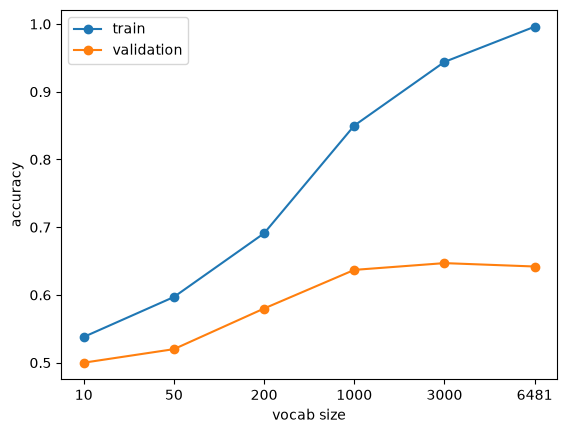

In [ ]:
import matplotlib.pyplot as plt

plt.plot(table['단어장 크기'],table['학습 정확도'],marker='o',label='train')
plt.plot(table['단어장 크기'],table['검증 정확도'],marker='o',label='validation')
plt.xlabel("vocab size")
plt.ylabel("accuracy")
plt.legend()
plt.show()

In [ ]:
import numpy as np

# 배송 빠르고 좋아요 벡터
# 배송 느리고 별로 벡터
# 느리고,배송,별로,빠르고,좋아요,최고
a = np.array([0,1,0,1,1,0])
b = np.array([1,1,1,0,0,0])

print(np.sqrt(((a - b) ** 2).sum()))

# numpy 메소드 이용
print(np.linalg.norm(a - b))

2.0
2.0


#### 로지스틱 회귀 
- 학습 시 : 특징별 가중치 (규칙)
- 예측 시 : 가중치로 계산만 하면 돼서 빠르다

#### KNN
- 학습 시 : 데이터 통째로 저장
- 예측 시 : 저장된 데이터 전부와 거리를 재야해서 느리다
- 조절하는 값 : k 값(사람이 정해주는 값-하이퍼 파라미터)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

for k in [1,5,15]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_tr,y_tr)
    print(k,"학습 : ",round(knn.score(X_tr,y_tr),3), "검증 : ",round(knn.score(X_val,y_val),3))

1 학습 :  0.998 검증 :  0.495
5 학습 :  0.707 검증 :  0.517
15 학습 :  0.592 검증 :  0.515


In [ ]:
# 정확도 평가
# 로지스틱 회귀(단어 전부)
# 로지스틱 회귀(단어 3000개)
# KNN(k=5)

candidates = {
    "로지스틱 회귀(단어 전부)":(CountVectorizer(),LogisticRegression(max_iter=1000)),
    "로지스틱 회귀(단어 3000개)":(CountVectorizer(max_features=3000),LogisticRegression(max_iter=1000)),
    "KNN(k=5)":(CountVectorizer(), KNeighborsClassifier(n_neighbors=5)),
}

for name, (v,m) in candidates.items():
    m.fit(v.fit_transform(text_tr), y_tr)
    print(name, "검증 정확도 : ",round(m.score(v.transform(text_val), y_val),3))


로지스틱 회귀(단어 전부) 검증 정확도 :  0.642
로지스틱 회귀(단어 3000개) 검증 정확도 :  0.647
KNN(k=5) 검증 정확도 :  0.517


In [ ]:
# 검증을 통해 로지스틱 회귀(단어 3000개) => 최종 테스트 한번
vec_final = CountVectorizer(max_features=3000)
X_train_all = vec_final.fit_transform(text_train)
best_model = LogisticRegression(max_iter=1000).fit(X_train_all,y_train)
print("최종 테스트 정확도 : ",round(best_model.score(vec_final.transform(text_test),y_test),3))

최종 테스트 정확도 :  0.718


#### 손실 최적화
- 학습 : 손실을 줄이는 방향으로 가중치를 조금씩 고치는 반복
- 손실 : 정답에 얼만큼 확신을 줬는가? 정답에 준 확률 p 로 손실( -log(p) )

In [ ]:
for p in [0.99, 0.9, 0.6, 0.5, 0.1, 0.01]:
    print(f"정답에 준 확률 :  {p:>4} (오답 확률 : {1-p:.2f}) -> 손실 {-np.log(p):.3f}")

정답에 준 확률 :  0.99 (오답 확률 : 0.01) -> 손실 0.010
정답에 준 확률 :   0.9 (오답 확률 : 0.10) -> 손실 0.105
정답에 준 확률 :   0.6 (오답 확률 : 0.40) -> 손실 0.511
정답에 준 확률 :   0.5 (오답 확률 : 0.50) -> 손실 0.693
정답에 준 확률 :   0.1 (오답 확률 : 0.90) -> 손실 2.303
정답에 준 확률 :  0.01 (오답 확률 : 0.99) -> 손실 4.605


In [ ]:
from sklearn.metrics import accuracy_score, log_loss
y_true = [1,0,1,1]

model_a = [0.55,0.45,0.51,0.60]
model_b = [0.95,0.05,0.90,0.97]

for name, prob in [("A",model_a),("B",model_b)]:
    pred = [1 if p > 0.5 else 0 for p in prob]
    print(name,"정확도",accuracy_score(y_true,pred), "손실 :",round(log_loss(y_true, prob),3))


A 정확도 1.0 손실 : 0.595
B 정확도 1.0 손실 : 0.06


#### 경사하강법
- 조금씩 고치기
- 새 가중치 = 현재 가중치 - 학습률 * 기울기
- 학습률이 너무 작으면 느리고, 너무 크면 확 넘어가버릴 수 있음

In [ ]:
np.linspace(0, 20, 100)
# 0~20 까지 100개 숫자 임의로 만들기

array([ 0.        ,  0.2020202 ,  0.4040404 ,  0.60606061,  0.80808081,
        1.01010101,  1.21212121,  1.41414141,  1.61616162,  1.81818182,
        2.02020202,  2.22222222,  2.42424242,  2.62626263,  2.82828283,
        3.03030303,  3.23232323,  3.43434343,  3.63636364,  3.83838384,
        4.04040404,  4.24242424,  4.44444444,  4.64646465,  4.84848485,
        5.05050505,  5.25252525,  5.45454545,  5.65656566,  5.85858586,
        6.06060606,  6.26262626,  6.46464646,  6.66666667,  6.86868687,
        7.07070707,  7.27272727,  7.47474747,  7.67676768,  7.87878788,
        8.08080808,  8.28282828,  8.48484848,  8.68686869,  8.88888889,
        9.09090909,  9.29292929,  9.49494949,  9.6969697 ,  9.8989899 ,
       10.1010101 , 10.3030303 , 10.50505051, 10.70707071, 10.90909091,
       11.11111111, 11.31313131, 11.51515152, 11.71717172, 11.91919192,
       12.12121212, 12.32323232, 12.52525253, 12.72727273, 12.92929293,
       13.13131313, 13.33333333, 13.53535354, 13.73737374, 13.93

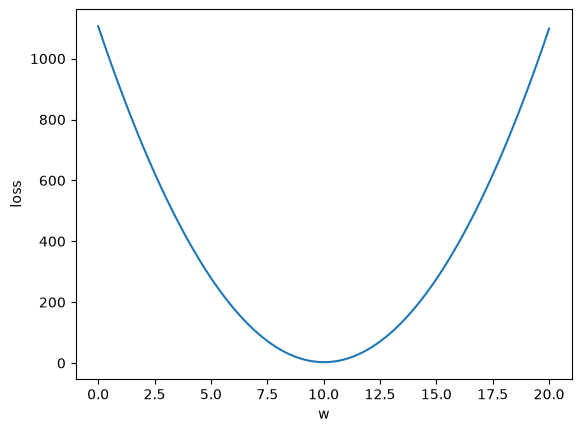

In [ ]:
# 공부시간 / 점수 변화

x = np.array([1,2,3,4,5])
y = np.array([12,19,31,42,48])

# 가상 가중치
ws = np.linspace(0, 20, 100)

losses = [ ((w * x - y)**2).mean() for w in ws ]
# ==  
# losses = []
# for w in ws :
# pred = w* x, error = pred -y , loss = (error **2).mean() losses.append(loss)

plt.plot(ws,losses)
plt.xlabel("w")
plt.ylabel("loss")
plt.show()

In [ ]:
def gradient_descent(lr, steps=30):
   w = 0.0
   for step in range(steps) : # step 1 번(1 epoch)
    pred = w * x
    loss = ((pred - y ) ** 2).mean()
    grad = (2 * (pred - y) * x).mean()
    w = w - lr * grad
    print(f"{step:2d} w={w:6.2f} loss={loss:10.1f}")

gradient_descent(lr=0.01)

 0 w=  2.20 loss=    1106.8
 1 w=  3.92 loss=     674.5
 2 w=  5.26 loss=     411.4
 3 w=  6.31 loss=     251.4
 4 w=  7.13 loss=     154.1
 5 w=  7.76 loss=      94.8
 6 w=  8.26 loss=      58.8
 7 w=  8.65 loss=      36.9
 8 w=  8.95 loss=      23.5
 9 w=  9.18 loss=      15.4
10 w=  9.37 loss=      10.5
11 w=  9.51 loss=       7.5
12 w=  9.62 loss=       5.6
13 w=  9.71 loss=       4.5
14 w=  9.78 loss=       3.8
15 w=  9.83 loss=       3.4
16 w=  9.87 loss=       3.2
17 w=  9.90 loss=       3.0
18 w=  9.93 loss=       2.9
19 w=  9.95 loss=       2.9
20 w=  9.96 loss=       2.8
21 w=  9.98 loss=       2.8
22 w=  9.99 loss=       2.8
23 w=  9.99 loss=       2.8
24 w= 10.00 loss=       2.8
25 w= 10.00 loss=       2.8
26 w= 10.01 loss=       2.8
27 w= 10.01 loss=       2.8
28 w= 10.01 loss=       2.8
29 w= 10.01 loss=       2.8


In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import log_loss

df = pd.read_csv("../data/reviews.csv")
text_tr, text_val, y_tr, y_val = train_test_split(
    df["text"], df["label"], test_size=0.25, random_state=42, stratify=df["label"])
vec = CountVectorizer()
X_tr = vec.fit_transform(text_tr)
X_val = vec.transform(text_val)

def train(lr, epochs=30):
    clf = SGDClassifier(loss="log_loss",             # 블록 A의 손실
                        learning_rate="constant",    # 학습률을 고정
                        eta0=lr,                     # 학습률 값
                        random_state=42)
    train_loss, val_loss = [], []
    for epoch in range(epochs):
        clf.partial_fit(X_tr, y_tr, classes=[0, 1])  # 학습 데이터를 한 번 더 보고 고침 = 1 에폭
        train_loss.append(log_loss(y_tr, clf.predict_proba(X_tr)))
        val_loss.append(log_loss(y_val, clf.predict_proba(X_val)))
    return train_loss, val_loss

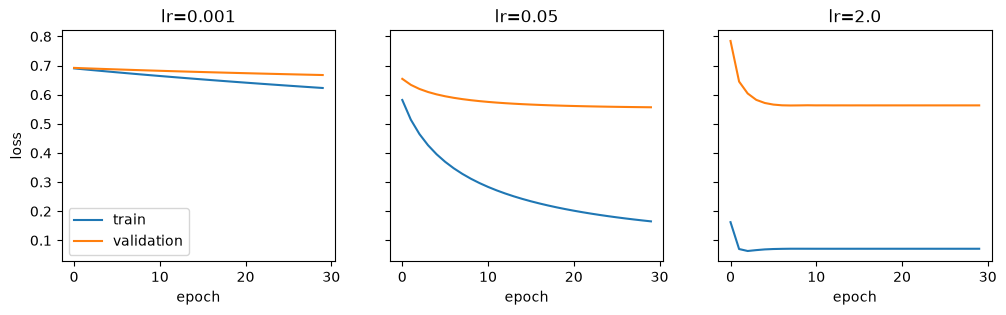

In [88]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, lr in zip(axes, [0.001, 0.05, 2.0]):
    tl, vl = train(lr)
    ax.plot(tl, label="train"); ax.plot(vl, label="validation")
    ax.set_title(f"lr={lr}"); ax.set_xlabel("epoch")
axes[0].set_ylabel("loss"); axes[0].legend(); plt.show()

#### 고객센터 문의 데이터
- label : 환불,상품,배송
- 고객 문의 문장을 세 개의 라벨 중 하나로 분류

In [145]:
# 데이터 로드 : pandas
df = pd.read_excel("../data/inquiries.xlsx")
# 상품, 환불, 배송 각 유형별 개수 확인
#nsmc = nsmc.dropna()

# nsmc.info()

#df = nsmc.groupby(['label'])
df['label'].value_counts()

label
배송    225
환불    150
상품    125
Name: count, dtype: int64

In [146]:
# 테스트 20% 분리
text_train,text_test,y_train,y_test = train_test_split(
    nsmc['text'],nsmc['label'],test_size=0.2,random_state=42,stratify=nsmc['label'])

print(len(text_train),len(text_test))

# 남은 데이터를 검증데이터 0.25
text_tr,text_val,y_tr,y_val = train_test_split(
    text_train,y_train,test_size=0.25,random_state=42,stratify=y_train)

print(len(text_tr),len(text_val))


400 100
300 100


In [153]:
# 벡터화 : 단어장 크기
rows = []
for size in [100,200,300,None]:
    vec = CountVectorizer(max_features=size)
    X_tr = vec.fit_transform(text_tr)
    X_val = vec.transform(text_val)

    #분류모델 
    # max_iter : 가중치 찾을 때 조금씩 고치기를 지정한 횟수만큼 할 수 있다
    # (손실이 더 이상 줄지 않으면 그 전에 멈춤)
    model = LogisticRegression(max_iter=1000)
    #학습(문장 벡터, 정답)
    model.fit(X_tr,y_tr)

    rows.append({"단어장 크기":str(X_tr.shape[1]),
                 "학습 정확도":round(model.score(X_tr,y_tr),3), 
                 "검증 정확도":round(model.score(X_val,y_val),3)})

table = pd.DataFrame(rows)
table


,단어장 크기,학습 정확도,검증 정확도
0,100,0.827,0.73
1,200,0.913,0.82
2,300,0.957,0.88
3,354,1.000,0.88


In [161]:
# 모델 2개 이상을 검증 데이터로 비교
# 분류모델

for k in [1,5,15]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_tr,y_tr)
    print(k,"학습 : ",round(knn.score(X_tr,y_tr),3), "검증 : ",round(knn.score(X_val,y_val),3))


knn = KNeighborsClassifier(n_neighbors=15).fit(X_tr,y_tr)
dist, idx = knn.kneighbors(vec.transform(['오늘 배송 오는 건가요?']))
print(text_tr.iloc[idx[0]].tolist())

1 학습 :  1.0 검증 :  0.79
5 학습 :  0.753 검증 :  0.66
15 학습 :  0.703 검증 :  0.67
['배송 언제 시작되나요?', '택배가엉뚱한데로가서반품하고싶어요', '문의드립니다배송언제시작되나요', '문의드립니다이색상품절인가요연락주세요', '주문번호20256760인데요해외배송되나요', '에어프라이어샀는데몇인용이에요연락주세요', '지난주에수분크림주문했어요취소철회하고싶어요빨리답변부탁드려요', '전기포트회수기사님이안오셨어요...', '급해요유통기한언제까지예요', '저기요AS는어디서받아요', '급해요새벽배송되나요확인부탁드립니다', '묶음배송가능한가요...', '부품이빠져있어서반품하고싶어요', '패딩샀는데택배상자가찢어져서왔어요...', '반품접수어떻게하나요']


In [170]:
# 고른 모델로 테스트 한번
vec_final = CountVectorizer(max_features=300)
# 학습+검증데이터
X_train_all = vec_final.fit_transform(text_train)
best_model = LogisticRegression(max_iter=1000).fit(X_train_all,y_train)
print("최종 테스트 정확도 : ",round(best_model.score(vec_final.transform(text_test),y_test),3))

최종 테스트 정확도 :  0.95


In [179]:
# 혼동 행렬과 오답 3개

# 테스트 데이터 벡터화
X_test_final = vec_final.transform(text_test)

pred = best_model.predict(X_test_final)
print(best_model.classes_)
print(confusion_matrix(y_test,pred, labels=best_model.classes_))
result = pd.DataFrame({"문장":text_test, "정답":y_test, "예측":pred})
wrong = result[result['정답']!= result['예측']]
print(len(wrong),"개 틀림")
wrong.head(3)


['배송' '상품' '환불']
[[45  0  0]
 [ 5 20  0]
 [ 0  0 30]]
5 개 틀림


,문장,정답,예측
349,쌀10kg샀는데냄새가나는데원래그런가요빨리답변부탁드려요,상품,배송
477,티셔츠몇인용이에요,상품,배송
42,유아도 써도 되나여 연락 주세여,상품,배송
